# LAB CHƯƠNG 3 — CANNY EDGE DETECTOR

Notebook được sắp xếp theo đúng **4 yêu cầu thực hành** trong slide. Mỗi mục gồm: **mục đích → xử lý → hiển thị kết quả → chỉ số/biểu đồ → nhận xét ngắn**.

**Ảnh đầu vào:** đặt ảnh trong thư mục `input/` nằm cạnh notebook. Mặc định notebook dùng `anh_mau_lab3.png` để có thể chạy ngay; nếu có ảnh riêng, đổi `IMAGE_FILENAME` ở phần 1. Không tải ảnh từ Internet.

**Kết quả:** ảnh và bảng số liệu được lưu trong thư mục `results/`.

**Lưu ý:** các ảnh nhiễu, tương phản thấp và nhiều chi tiết ở phần III được tạo từ ảnh đầu vào để so sánh có kiểm soát.


# I. CƠ SỞ LÝ THUYẾT VỀ CANNY

## I.1. Mục tiêu và quy trình 5 bước

Canny là thuật toán phát hiện biên nhằm tạo ra đường biên **mảnh, liên tục và hạn chế biên giả**. Quy trình thường được trình bày qua 5 bước:

1. **Làm trơn bằng Gaussian:** giảm nhiễu và các biến thiên cường độ nhỏ trước khi tính gradient. Sigma (\(\sigma\)) càng lớn thì mức làm trơn càng mạnh; đổi lại, chi tiết nhỏ và biên gần nhau có thể bị mất hoặc nhập lại.
2. **Tính gradient:** ước lượng độ thay đổi cường độ theo hai hướng \(x\) và \(y\). Độ lớn gradient cho biết biên mạnh hay yếu; hướng gradient hỗ trợ bước làm mảnh.
3. **Non-Maximum Suppression (NMS):** chỉ giữ điểm có độ lớn gradient cực đại theo hướng gradient, loại các điểm lân cận không phải cực đại để làm biên mảnh hơn.
4. **Double Threshold:** dùng ngưỡng cao và ngưỡng thấp để chia điểm thành biên mạnh, biên yếu và điểm không phải biên. Điểm vượt ngưỡng cao là biên mạnh; điểm nằm giữa hai ngưỡng là biên yếu; điểm dưới ngưỡng thấp bị loại.
5. **Edge Tracking by Hysteresis:** giữ biên yếu nếu chúng liên kết với biên mạnh; loại biên yếu không liên kết. Cách này giúp giữ đường biên có tính liên tục mà hạn chế nhiễu.

## I.2. Vai trò của các tham số

- **Sigma (\(\sigma\)):** điều khiển Gaussian smoothing. Sigma nhỏ giữ nhiều chi tiết nhưng dễ nhạy với nhiễu; sigma lớn giảm nhiễu tốt hơn nhưng có thể làm mất biên mảnh.
- **Ngưỡng thấp (low threshold):** quyết định điểm yếu nào có thể được xem xét giữ lại nếu nối với biên mạnh.
- **Ngưỡng cao (high threshold):** xác định các điểm biên mạnh làm điểm neo cho hysteresis.
- Thông thường cần bảo đảm `low_threshold < high_threshold`. Không có một cặp ngưỡng tối ưu cho tất cả ảnh; phải quan sát kết quả theo dữ liệu.

## I.3. So sánh Canny, Sobel và Laplacian

| Phương pháp | Cơ chế chính | Điểm mạnh | Hạn chế |
|---|---|---|---|
| Sobel | Đạo hàm bậc nhất theo X/Y, thường lấy độ lớn gradient | Đơn giản, nhanh, cho biết hướng biến thiên | Có thể tạo biên dày/nhiễu; không tự thực hiện NMS và hysteresis |
| Laplacian | Đạo hàm bậc hai, phản ánh biến thiên theo nhiều hướng | Phát hiện biến thiên cường độ theo nhiều hướng | Nhạy với nhiễu; thường cần làm trơn và quy tắc xác định zero-crossing |
| Canny | Gaussian + gradient + NMS + double threshold + hysteresis | Biên thường mảnh, liên tục và kiểm soát nhiễu tốt hơn khi chọn tham số phù hợp | Nhiều tham số hơn, tính toán thường phức tạp hơn; kết quả phụ thuộc ảnh và cấu hình |

Canny **không phải lúc nào cũng tốt hơn** Sobel/Laplacian trong mọi tác vụ. Nếu chỉ cần gradient nhanh, Sobel có thể đủ; nếu cần đường biên mảnh và liên tục, Canny thường phù hợp hơn.

## I.4. Ưu điểm, hạn chế và ứng dụng

**Ưu điểm:** giảm nhiễu trước khi tính gradient; làm mảnh đường biên bằng NMS; hysteresis giúp giữ biên yếu có liên kết với biên mạnh.

**Hạn chế:** phải chọn sigma và hai ngưỡng; tham số không phù hợp có thể làm mất biên hoặc sinh nhiều biên giả; Canny chỉ tạo bản đồ cạnh, chưa tự hiểu đối tượng hay phân đoạn ngữ nghĩa.

**Ứng dụng thường gặp:** tiền xử lý cho phân đoạn ảnh, trích xuất đường bao, nhận dạng hình dạng, đo kích thước/biên dạng, kiểm tra lỗi bề mặt và một số bước xử lý trong thị giác robot.



## 0. Thư viện và thiết lập

Các thư viện chính: OpenCV và Scikit-image để phát hiện cạnh; NumPy để xử lý ma trận ảnh; Matplotlib để hiển thị; Pandas để tổng hợp số liệu.

In [1]:
import os
# Nếu thiếu thư viện, bỏ dấu # và chạy lệnh sau:
# %pip install opencv-python numpy matplotlib scikit-image scipy pandas

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from pathlib import Path
from skimage import feature
from IPython.display import display

SEED = 42
np.random.seed(SEED)
INPUT_DIR = Path("input")
OUTPUT_DIR = Path("results")
INPUT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Scikit-image:", __import__("skimage").__version__)

OpenCV: 5.0.0
NumPy: 2.5.4
Scikit-image: 0.26.0


## 1. Đọc ảnh do người dùng cung cấp

Đặt ảnh trong `input/`. Mặc định dùng `anh_mau_lab3.png` đi kèm gói Lab 3. Nếu muốn dùng ảnh riêng, đổi `IMAGE_FILENAME` thành tên file ảnh của bạn.

Ảnh: anh_mau_lab3.png | Kích thước: 560 x 560 | dtype: uint8


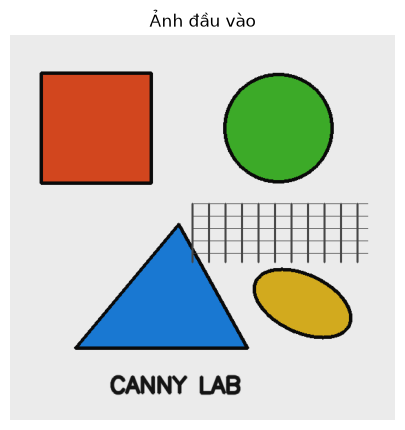

In [2]:
IMAGE_FILENAME = "anh_mau_lab3.png"  # Ví dụ: "anh_cua_toi.jpg"

extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
image_files = sorted(p for p in INPUT_DIR.iterdir()
                     if p.is_file() and p.suffix.lower() in extensions)
if not image_files:
    raise FileNotFoundError("Thư mục input/ chưa có ảnh. Hãy chép ảnh vào đây.")

image_path = INPUT_DIR / IMAGE_FILENAME
if not image_path.is_file():
    if len(image_files) == 1:
        image_path = image_files[0]
        print("Không tìm thấy tên mặc định; tự chọn ảnh duy nhất:", image_path.name)
    else:
        raise FileNotFoundError(f"Không tìm thấy {IMAGE_FILENAME}. Hãy sửa IMAGE_FILENAME.")

image = cv2.imdecode(np.fromfile(str(image_path), dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Không đọc được ảnh: {image_path}")

# Giới hạn kích thước để notebook chạy ổn định trên máy cá nhân.
max_side = 800
h, w = image.shape[:2]
scale = min(1.0, max_side / max(h, w))
if scale < 1:
    image = cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
height, width = gray.shape
print(f"Ảnh: {image_path.name} | Kích thước: {width} x {height} | dtype: {image.dtype}")

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Ảnh đầu vào")
plt.axis("off")
plt.show()

## Hàm hỗ trợ hiển thị, lưu ảnh và đo chỉ số

Các chỉ số được dùng trong Lab 3:
- **Edge density:** tỷ lệ pixel được đánh dấu là cạnh.
- **Thời gian xử lý:** thời gian chạy của phép toán, đo bằng `time.perf_counter()`.
- Các chỉ số này hỗ trợ so sánh thực nghiệm; edge density cao không đồng nghĩa với độ chính xác cao.

In [3]:
def show_grid(items, cols=2, figsize=(14, 8)):
    rows = int(np.ceil(len(items) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, item in zip(axes.flat, items):
        title, img = item[0], item[1]
        cmap = item[2] if len(item) > 2 else None
        if img.ndim == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img, cmap=cmap or "gray", vmin=0, vmax=255 if img.dtype == np.uint8 else None)
        ax.set_title(title, fontsize=11, fontweight="bold")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def save_img(name, img):
    path = OUTPUT_DIR / name
    ok, encoded = cv2.imencode(path.suffix or ".png", img)
    if not ok:
        raise IOError(f"Không lưu được {path}")
    encoded.tofile(str(path))
    return path


def edge_density(edges):
    return 100.0 * np.count_nonzero(edges) / edges.size


def show_table(headers, rows, title=None, decimals=3):
    formatted = []
    for row in rows:
        formatted.append([f"{v:.{decimals}f}" if isinstance(v, (int, float, np.integer, np.floating)) else str(v)
                          for v in row])
    fig, ax = plt.subplots(figsize=(max(7, len(headers) * 2), 0.65 + 0.42 * (len(rows) + 1)))
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    table = ax.table(cellText=formatted, colLabels=headers, loc="center", cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.5)
    plt.tight_layout()
    plt.show()


def save_figure(name):
    path = OUTPUT_DIR / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Đã lưu biểu đồ:", path)


# I. CANNY BẰNG OPENCV VÀ SCIKIT-IMAGE

Thực hiện Canny bằng hai thư viện theo yêu cầu đề bài. Sau đó đối chiếu trực quan với Sobel và Laplacian.

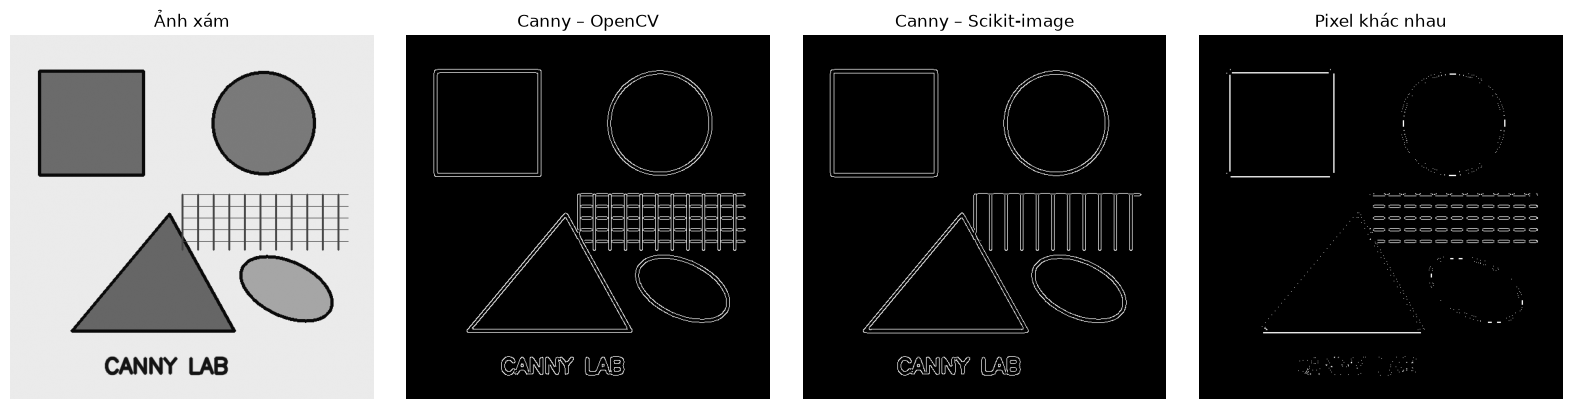

,Phương pháp,Thời gian TB (ms),Độ lệch chuẩn (ms),Tỷ lệ pixel cạnh (%)
0,Canny – OpenCV,0.478,0.176,3.120
1,Canny – Scikit-image,14.264,0.275,2.494


Lưu ý: đây là so sánh thời gian trên máy đang chạy notebook. Hai thư viện có cách cài đặt và quy ước tham số khác nhau,
nên cặp ngưỡng quy đổi chỉ mang tính tham khảo; không thể kết luận tốc độ/độ chính xác tổng quát từ một ảnh.


In [4]:
# So sánh thời gian theo cùng phạm vi: cả hai phép đo đều tính cả bước làm trơn.
# Lặp nhiều lần để giảm ảnh hưởng của dao động hệ thống; báo cáo thời gian trung bình.
SIGMA_COMPARE = 1.4
LOW_COMPARE, HIGH_COMPARE = 50, 150
gray_float = gray.astype(np.float32) / 255.0

def run_opencv_canny_full():
    blurred = cv2.GaussianBlur(gray, (5, 5), SIGMA_COMPARE)
    return cv2.Canny(blurred, LOW_COMPARE, HIGH_COMPARE)

def run_skimage_canny_full():
    return feature.canny(
        gray_float,
        sigma=SIGMA_COMPARE,
        low_threshold=LOW_COMPARE / 255.0,
        high_threshold=HIGH_COMPARE / 255.0
    )

# Chạy một lượt khởi động trước khi đo.
edges_cv = run_opencv_canny_full()
edges_sk = run_skimage_canny_full()

def benchmark_ms(function, repeats=10):
    samples = []
    result = None
    for _ in range(repeats):
        t0 = time.perf_counter()
        result = function()
        samples.append((time.perf_counter() - t0) * 1000)
    return result, float(np.mean(samples)), float(np.std(samples, ddof=1)) if repeats > 1 else 0.0

edges_cv, time_cv, std_cv = benchmark_ms(run_opencv_canny_full, repeats=10)
edges_sk, time_sk, std_sk = benchmark_ms(run_skimage_canny_full, repeats=10)
edges_sk_u8 = (edges_sk.astype(np.uint8) * 255)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
items = [(gray, "Ảnh xám"), (edges_cv, "Canny – OpenCV"),
         (edges_sk_u8, "Canny – Scikit-image"),
         (cv2.absdiff(edges_cv, edges_sk_u8), "Pixel khác nhau")]
for ax, (im, title) in zip(axes, items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
save_img("I1_canny_opencv.png", edges_cv)
save_img("I1_canny_skimage.png", edges_sk_u8)
save_img("I1_khac_biet_hai_thu_vien.png", cv2.absdiff(edges_cv, edges_sk_u8))

bang_so_sanh = pd.DataFrame([
    ["Canny – OpenCV", time_cv, std_cv, edge_density(edges_cv)],
    ["Canny – Scikit-image", time_sk, std_sk, edge_density(edges_sk_u8)]
], columns=["Phương pháp", "Thời gian TB (ms)", "Độ lệch chuẩn (ms)", "Tỷ lệ pixel cạnh (%)"])
display(bang_so_sanh.round(3))

print("Lưu ý: đây là so sánh thời gian trên máy đang chạy notebook. Hai thư viện có cách cài đặt và quy ước tham số khác nhau,")
print("nên cặp ngưỡng quy đổi chỉ mang tính tham khảo; không thể kết luận tốc độ/độ chính xác tổng quát từ một ảnh.")


**Nhận xét cần ghi nhận:** hai thư viện đều triển khai Canny nhưng kết quả không nhất thiết trùng khít. Cách tính gradient, quy ước ngưỡng và chi tiết triển khai có thể khác nhau. Trong cell trên, ảnh đầu vào và sigma được giữ tương ứng; ngưỡng Scikit-image được chuẩn hóa theo ảnh float [0, 1]. Vì vậy đây là so sánh thực nghiệm gần tương đương, không phải khẳng định hai thuật toán có đầu ra pixel-identical.

### I.2. So sánh với Sobel và Laplacian

Sobel phát hiện biến thiên theo hai hướng X/Y; Laplacian sử dụng đạo hàm bậc hai; Canny kết hợp làm trơn, triệt cực đại không cục bộ và ngưỡng kép.

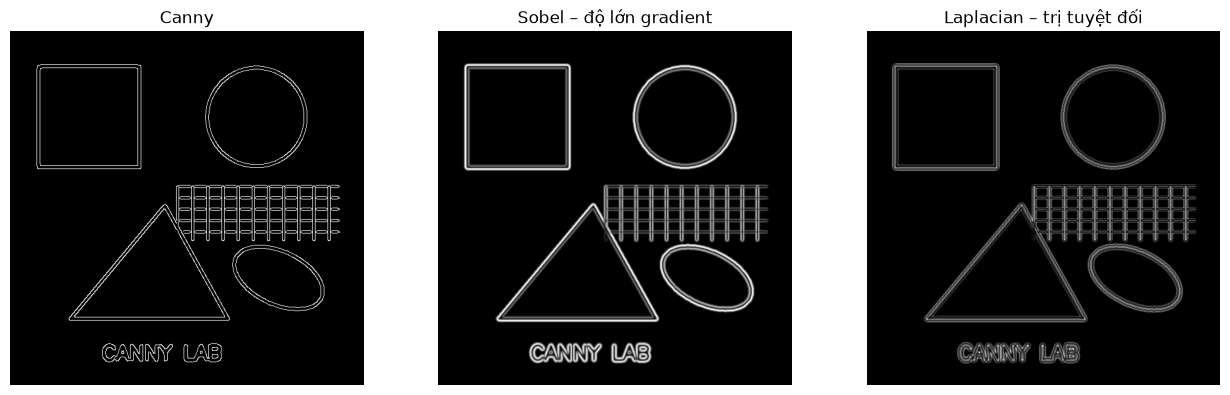

WindowsPath('results/I2_laplacian.png')

In [5]:
blur = cv2.GaussianBlur(gray, (5, 5), 1.4)

sobel_x = cv2.Sobel(blur, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blur, cv2.CV_32F, 0, 1, ksize=3)
sobel_mag = cv2.magnitude(sobel_x, sobel_y)
sobel_img = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

laplacian = cv2.Laplacian(blur, cv2.CV_32F, ksize=3)
laplacian_img = cv2.normalize(np.abs(laplacian), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, im, title in zip(axes, [edges_cv, sobel_img, laplacian_img],
                         ["Canny", "Sobel – độ lớn gradient", "Laplacian – trị tuyệt đối"]):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
save_img("I2_sobel.png", sobel_img)
save_img("I2_laplacian.png", laplacian_img)


**Kết luận:** Sobel ước lượng gradient theo từng hướng, Laplacian dựa trên đạo hàm bậc hai; ảnh kết quả dạng độ lớn thường còn nhiều mức xám và có thể tạo biên dày. Canny có thêm làm trơn, triệt cực đại không cục bộ và ngưỡng kép nên thường tạo đường biên mảnh, dễ kiểm soát hơn. Không nên kết luận thuật toán nào luôn chính xác/tốc độ hơn trong mọi trường hợp nếu chưa đo trên cùng dữ liệu và cấu hình.

# II. KHẢO SÁT THAM SỐ CANNY

Thay đổi sigma, ngưỡng thấp và ngưỡng cao; quan sát ảnh đầu ra, tỷ lệ pixel cạnh và so sánh với cấu hình mặc định.

### 5.1. Ảnh hưởng của sigma

Sigma điều khiển độ rộng Gaussian. Sigma nhỏ giữ lại nhiều chi tiết nhưng dễ giữ cả nhiễu; sigma lớn làm trơn mạnh hơn nhưng có thể làm mất cạnh nhỏ.

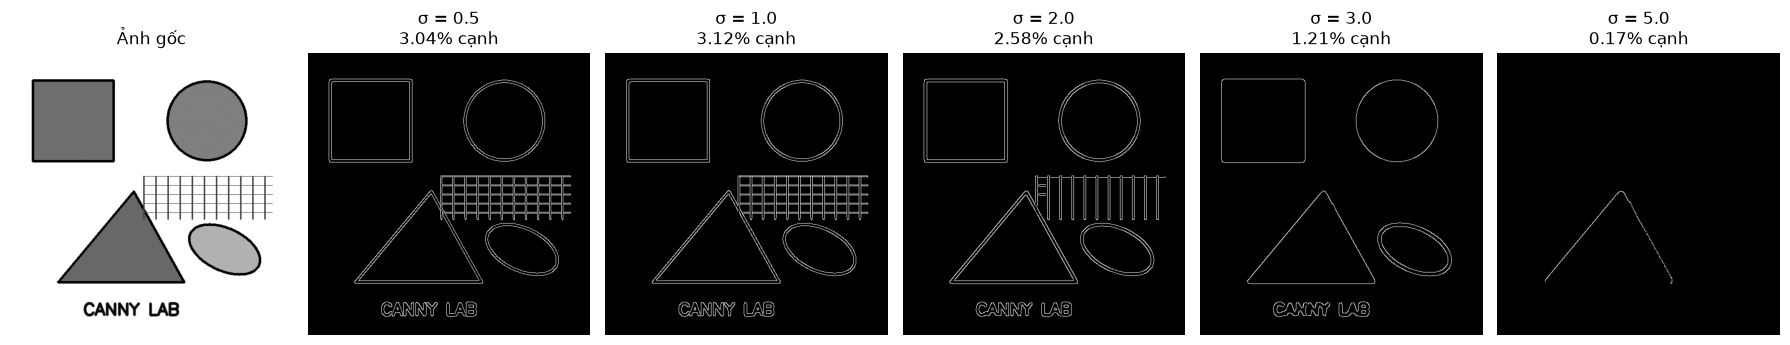

,Sigma,Tỷ lệ pixel cạnh (%)
0,0.5,3.043
1,1.0,3.118
2,2.0,2.580
3,3.0,1.207
4,5.0,0.168


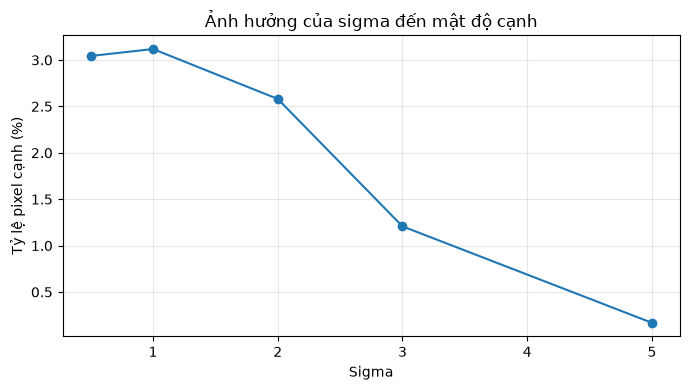

Đã lưu biểu đồ: results\II1_bieu_do_sigma_edge_density.png


<Figure size 640x480 with 0 Axes>

In [6]:
def canny_opencv_sigma(gray_img, sigma, low=50, high=150):
    if sigma > 0:
        ksize = max(3, int(6 * sigma + 1) | 1)  # kernel lẻ, xấp xỉ 6*sigma
        smoothed = cv2.GaussianBlur(gray_img, (ksize, ksize), sigma)
    else:
        smoothed = gray_img
    return cv2.Canny(smoothed, low, high)

sigmas = [0.5, 1.0, 2.0, 3.0, 5.0]
fig, axes = plt.subplots(1, len(sigmas) + 1, figsize=(18, 4))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("Ảnh gốc"); axes[0].axis("off")
rows = []
for ax, sigma in zip(axes[1:], sigmas):
    edge = canny_opencv_sigma(gray, sigma, 50, 150)
    ratio = edge_density(edge)
    ax.imshow(edge, cmap="gray"); ax.set_title(f"σ = {sigma}\n{ratio:.2f}% cạnh"); ax.axis("off")
    rows.append([sigma, ratio])
plt.tight_layout(); plt.show()
for sigma in sigmas:
    save_img(f"II1_sigma_{str(sigma).replace('.', '_')}.png", canny_opencv_sigma(gray, sigma, 50, 150))
display(pd.DataFrame(rows, columns=["Sigma", "Tỷ lệ pixel cạnh (%)"]).round(3))


# Biểu đồ xu hướng: sigma và tỷ lệ pixel cạnh (chỉ là chỉ số mật độ, không phải độ chính xác).
sigma_df = pd.DataFrame(rows, columns=["Sigma", "Tỷ lệ pixel cạnh (%)"])
plt.figure(figsize=(7, 4))
plt.plot(sigma_df["Sigma"], sigma_df["Tỷ lệ pixel cạnh (%)"], marker="o")
plt.xlabel("Sigma")
plt.ylabel("Tỷ lệ pixel cạnh (%)")
plt.title("Ảnh hưởng của sigma đến mật độ cạnh")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
save_figure("II1_bieu_do_sigma_edge_density.png")


### 5.2. Ảnh hưởng của ngưỡng thấp và ngưỡng cao

Ngưỡng thấp giúp quyết định pixel yếu nào có thể được giữ lại khi liên kết với cạnh mạnh. Ngưỡng cao quyết định pixel nào được xem là cạnh mạnh. Thông thường ngưỡng cao lớn hơn ngưỡng thấp.

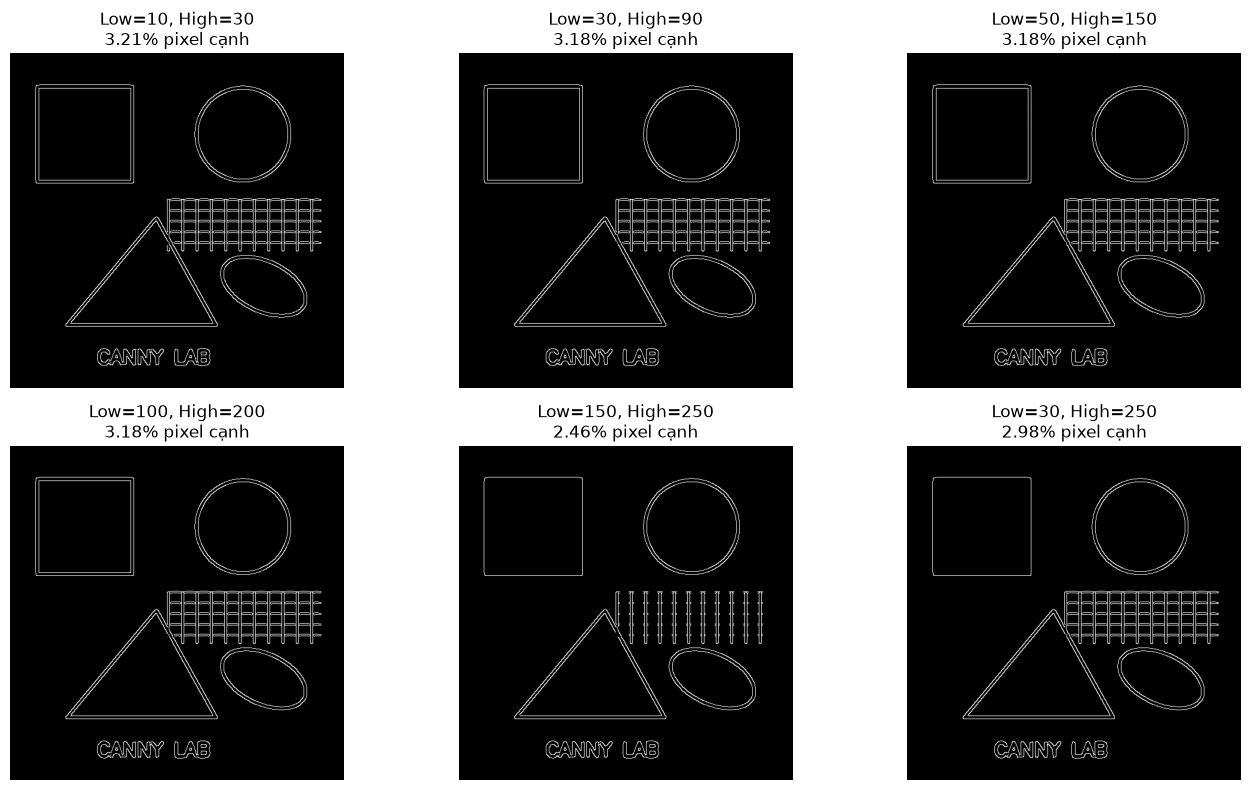

,Ngưỡng thấp,Ngưỡng cao,Tỷ lệ pixel cạnh (%)
0,10,30,3.214
1,30,90,3.181
2,50,150,3.180
3,100,200,3.178
4,150,250,2.464
5,30,250,2.983


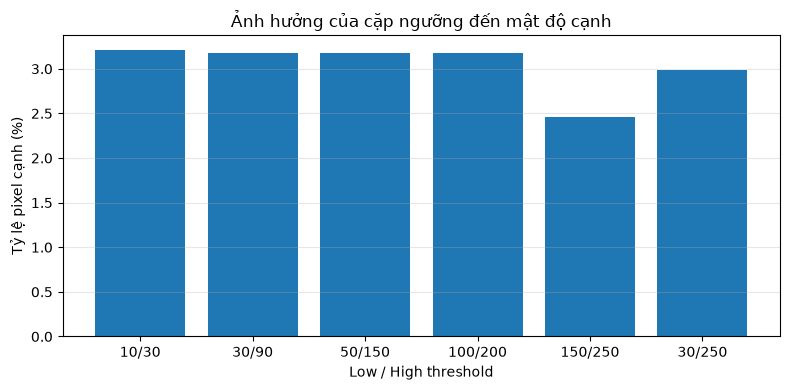

Đã lưu biểu đồ: results\II2_bieu_do_threshold_edge_density.png


<Figure size 640x480 with 0 Axes>

In [7]:
threshold_pairs = [(10, 30), (30, 90), (50, 150), (100, 200), (150, 250), (30, 250)]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
rows = []
for ax, (low, high) in zip(axes.ravel(), threshold_pairs):
    edge = canny_opencv_sigma(gray, 1.4, low, high)
    ratio = edge_density(edge)
    ax.imshow(edge, cmap="gray")
    ax.set_title(f"Low={low}, High={high}\n{ratio:.2f}% pixel cạnh")
    ax.axis("off")
    rows.append([low, high, ratio])
plt.tight_layout(); plt.show()
for low, high in threshold_pairs:
    save_img(f"II2_threshold_{low}_{high}.png", canny_opencv_sigma(gray, 1.4, low, high))
display(pd.DataFrame(rows, columns=["Ngưỡng thấp", "Ngưỡng cao", "Tỷ lệ pixel cạnh (%)"]).round(3))


threshold_df = pd.DataFrame(rows, columns=["Ngưỡng thấp", "Ngưỡng cao", "Tỷ lệ pixel cạnh (%)"])
plt.figure(figsize=(8, 4))
labels = [f"{lo}/{hi}" for lo, hi, _ in rows]
plt.bar(labels, [ratio for _, _, ratio in rows])
plt.xlabel("Low / High threshold")
plt.ylabel("Tỷ lệ pixel cạnh (%)")
plt.title("Ảnh hưởng của cặp ngưỡng đến mật độ cạnh")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
save_figure("II2_bieu_do_threshold_edge_density.png")


### 5.3. So sánh cấu hình mặc định và cấu hình tùy chỉnh

Lưu ý: mặc định của mỗi thư viện không hoàn toàn giống nhau. OpenCV yêu cầu ngưỡng đầu vào; Scikit-image có cấu hình mặc định riêng (sigma và ngưỡng tự động theo dữ liệu).

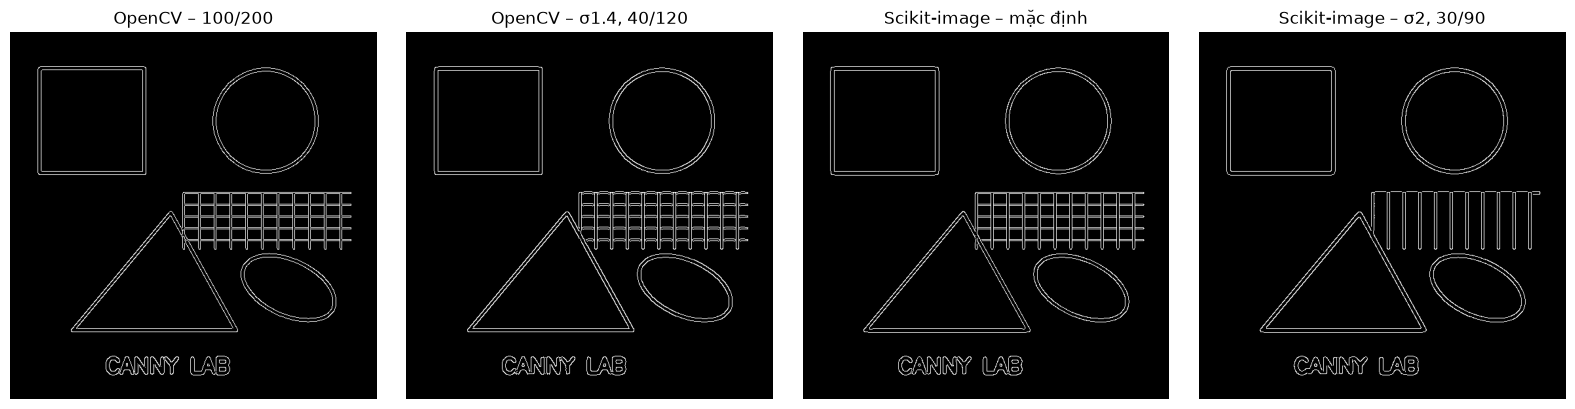

WindowsPath('results/II3_skimage_tuy_chinh.png')

In [8]:
# OpenCV mặc định thường dùng trong ví dụ: threshold 100/200, không Gaussian tường minh.
cv_default = cv2.Canny(gray, 100, 200)
# OpenCV cấu hình tùy chỉnh.
cv_custom = canny_opencv_sigma(gray, 1.4, 40, 120)
# Scikit-image mặc định.
sk_default = feature.canny(gray_float)
# Scikit-image tùy chỉnh.
sk_custom = feature.canny(gray_float, sigma=2.0,
                          low_threshold=30/255.0, high_threshold=90/255.0)

compare_items = [(cv_default, "OpenCV – 100/200"), (cv_custom, "OpenCV – σ1.4, 40/120"),
                 (sk_default, "Scikit-image – mặc định"), (sk_custom, "Scikit-image – σ2, 30/90")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (edge, title) in zip(axes, compare_items):
    ax.imshow(edge, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
save_img("II3_opencv_mac_dinh.png", cv_default)
save_img("II3_opencv_tuy_chinh.png", cv_custom)
save_img("II3_skimage_mac_dinh.png", (sk_default.astype(np.uint8) * 255))
save_img("II3_skimage_tuy_chinh.png", (sk_custom.astype(np.uint8) * 255))


**Nhận xét:** sigma tăng thường làm giảm các chi tiết nhỏ và cạnh do nhiễu. Tăng cả hai ngưỡng thường làm giảm số pixel cạnh được giữ lại; ngưỡng quá cao có thể làm đứt hoặc mất cạnh yếu. Cấu hình tốt phụ thuộc nội dung, độ sáng, độ tương phản và mức nhiễu của ảnh.

# III. CANNY TRÊN CÁC LOẠI ẢNH

Thử nghiệm với ảnh nhiều nhiễu, ảnh tương phản thấp và ảnh nhiều chi tiết. Các biến thể được tạo từ cùng ảnh đầu vào để giữ điều kiện so sánh nhất quán.

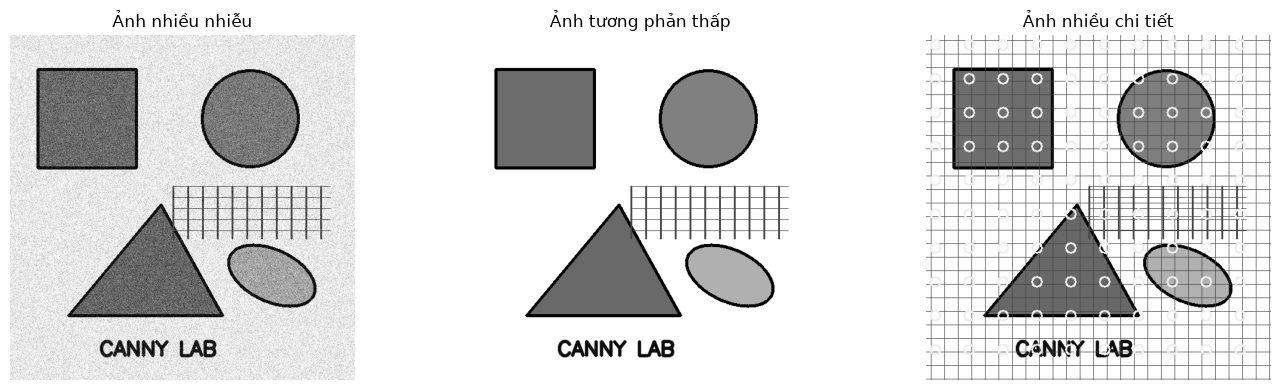

WindowsPath('results/III0_nhieu_chi_tiet.png')

In [9]:
rng = np.random.default_rng(42)

# Ảnh nhiều nhiễu: cộng nhiễu Gaussian.
noise = rng.normal(0, 24, gray.shape)
image_noisy = np.clip(gray.astype(np.float32) + noise, 0, 255).astype(np.uint8)

# Ảnh tương phản thấp: co dải cường độ quanh mức xám 128.
image_low_contrast = np.clip(128 + 0.30 * (gray.astype(np.float32) - 128), 0, 255).astype(np.uint8)

# Ảnh nhiều chi tiết: tạo lưới đường, vòng tròn và họa tiết nhỏ.
image_detailed = gray.copy()
H, W = image_detailed.shape
for x in range(8, W, 22): cv2.line(image_detailed, (x, 0), (x, H-1), 70, 1)
for y in range(8, H, 22): cv2.line(image_detailed, (0, y), (W-1, y), 70, 1)
for x in range(15, W, 55):
    for y in range(15, H, 55): cv2.circle(image_detailed, (x, y), 8, 220, 2)

image_cases = {
    "Ảnh nhiều nhiễu": image_noisy,
    "Ảnh tương phản thấp": image_low_contrast,
    "Ảnh nhiều chi tiết": image_detailed
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, im) in zip(axes, image_cases.items()):
    ax.imshow(im, cmap="gray"); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()
save_img("III0_anh_nhieu.png", image_noisy)
save_img("III0_tuong_phan_thap.png", image_low_contrast)
save_img("III0_nhieu_chi_tiet.png", image_detailed)


### 6.1. So sánh Canny không làm trơn và có Gaussian + ngưỡng tự động

Ngưỡng tự động theo median trong code là một heuristic, không phải ngưỡng tối ưu cho mọi ảnh.

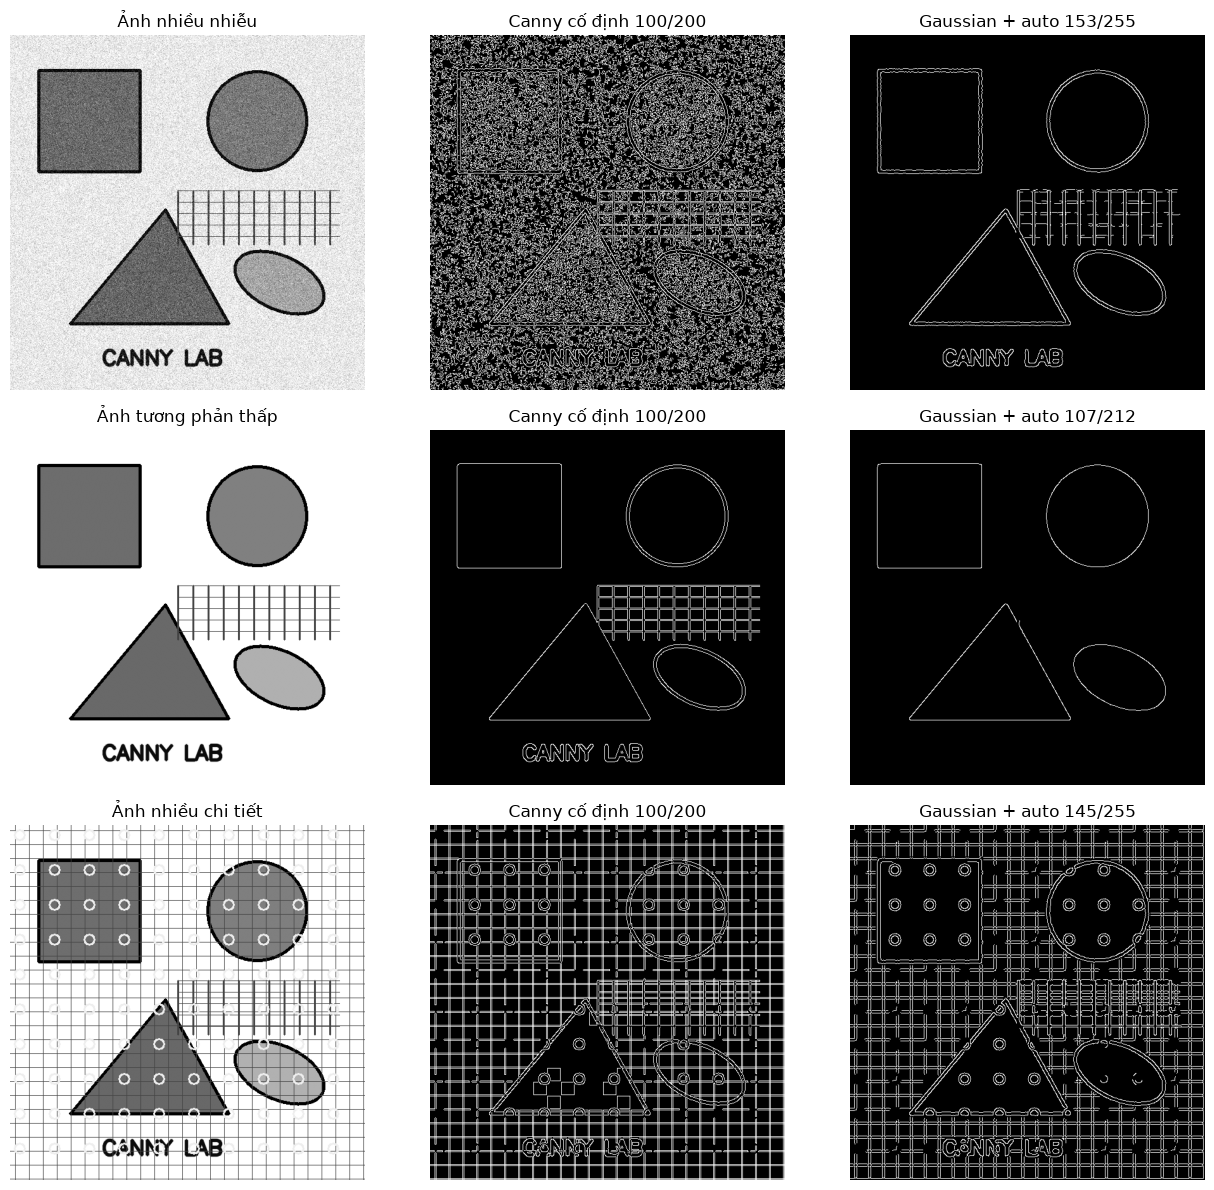

,Loại ảnh,Canny cố định (%),Gaussian + auto (%),Low auto,High auto
0,Ảnh nhiều nhiễu,27.378,2.822,153,255
1,Ảnh tương phản thấp,2.557,0.785,107,212
2,Ảnh nhiều chi tiết,17.940,13.263,145,255


In [10]:
def canny_auto_median(gray_img, sigma_factor=0.33, blur_sigma=1.4):
    smooth = cv2.GaussianBlur(gray_img, (5, 5), blur_sigma)
    median = float(np.median(smooth))
    low = int(max(0, (1.0 - sigma_factor) * median))
    high = int(min(255, (1.0 + sigma_factor) * median))
    if high <= low: high = min(255, low + 1)
    return cv2.Canny(smooth, low, high), low, high

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
summary = []
for row, (name, im) in enumerate(image_cases.items()):
    raw = cv2.Canny(im, 100, 200)
    auto, low, high = canny_auto_median(im)
    for ax, result, title in zip(axes[row], [im, raw, auto],
                                 [name, "Canny cố định 100/200", f"Gaussian + auto {low}/{high}"]):
        ax.imshow(result, cmap="gray"); ax.set_title(title); ax.axis("off")
    summary.append([name, edge_density(raw), edge_density(auto), low, high])
plt.tight_layout(); plt.show()
for case_name, case_img in image_cases.items():
    safe_name = case_name.lower().replace(" ", "_")
    save_img(f"III1_{safe_name}_canny_co_dinh.png", cv2.Canny(case_img, 100, 200))
    auto_edges, _, _ = canny_auto_median(case_img)
    save_img(f"III1_{safe_name}_gaussian_auto.png", auto_edges)
display(pd.DataFrame(summary, columns=["Loại ảnh", "Canny cố định (%)", "Gaussian + auto (%)", "Low auto", "High auto"]).round(3))


### 6.2. Đánh giá và kết luận

- **Ảnh nhiều nhiễu:** thường xuất hiện nhiều cạnh giả nếu xử lý trực tiếp; Gaussian trước Canny giúp giảm nhiễu nhưng sigma quá lớn có thể xóa cạnh nhỏ.
- **Ảnh tương phản thấp:** gradient yếu nên ngưỡng cố định có thể bỏ sót cạnh; cần thử ngưỡng thấp hơn hoặc phương pháp tự động, đồng thời kiểm tra nguy cơ tăng cạnh giả.
- **Ảnh nhiều chi tiết:** có thể tạo mật độ cạnh cao; tăng sigma/ngưỡng có thể giảm chi tiết không cần thiết nhưng cũng có thể làm mất cấu trúc nhỏ.

Tỷ lệ pixel cạnh chỉ phản ánh mật độ cạnh, **không đồng nghĩa với độ chính xác**. Muốn đánh giá định lượng chất lượng thực sự cần ảnh cạnh chuẩn (ground truth) được gán nhãn.


## III.3. Thử nghiệm bổ sung trên ảnh tự nhiên

Ba ảnh thử nghiệm phía trên được tạo có kiểm soát từ ảnh đầu vào. Để tránh chỉ kết luận trên ảnh minh họa nhân tạo, phần này chạy thêm Canny trên ảnh tự nhiên `camera` có sẵn trong Scikit-image. Đây là ví dụ bổ sung; kết quả có thể khác khi thay ảnh.



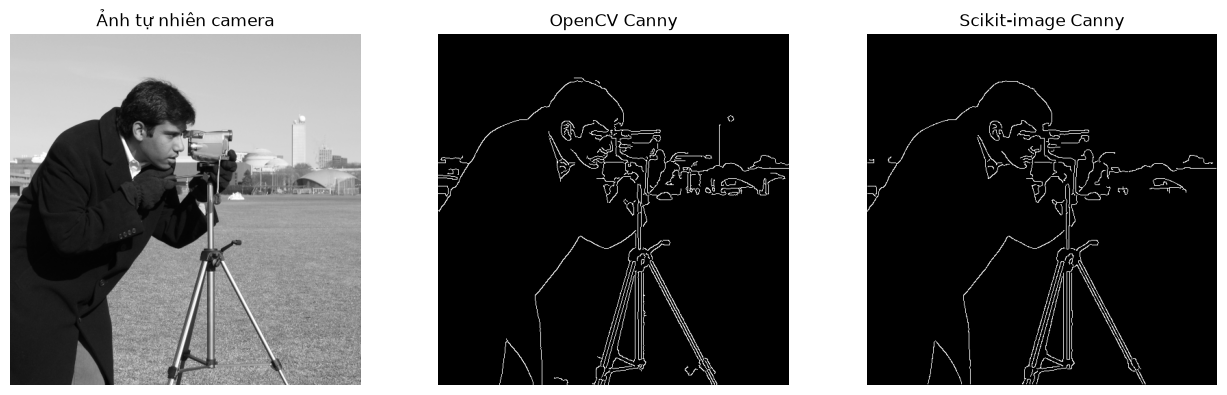

,Phương pháp,Tỷ lệ pixel cạnh (%)
0,OpenCV,2.868
1,Scikit-image,2.349


In [11]:
from skimage import data

natural_gray = data.camera()  # Ảnh tự nhiên grayscale 512 × 512
natural_edges = cv2.Canny(
    cv2.GaussianBlur(natural_gray, (5, 5), 1.4), 50, 150
)
natural_edges_sk = feature.canny(
    natural_gray.astype(np.float32) / 255.0,
    sigma=1.4, low_threshold=50/255.0, high_threshold=150/255.0
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, im, title in zip(
    axes, [natural_gray, natural_edges, natural_edges_sk],
    ["Ảnh tự nhiên camera", "OpenCV Canny", "Scikit-image Canny"]
):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
save_img("III3_anh_tu_nhien_camera.png", natural_gray)
save_img("III3_canny_opencv.png", natural_edges)
save_img("III3_canny_skimage.png", (natural_edges_sk.astype(np.uint8) * 255))
display(pd.DataFrame([
    ["OpenCV", edge_density(natural_edges)],
    ["Scikit-image", edge_density(natural_edges_sk.astype(np.uint8) * 255)]
], columns=["Phương pháp", "Tỷ lệ pixel cạnh (%)"]).round(3))


# IV. KẾT HỢP CANNY VỚI PHÂN ĐOẠN VÀ NHẬN DẠNG

Dùng morphology để nối các đoạn biên, contour để tách vùng, `approxPolyDP` để phân loại hình dạng và Hough Circle để tìm đường tròn.

Số vùng contour sau lọc diện tích: 4


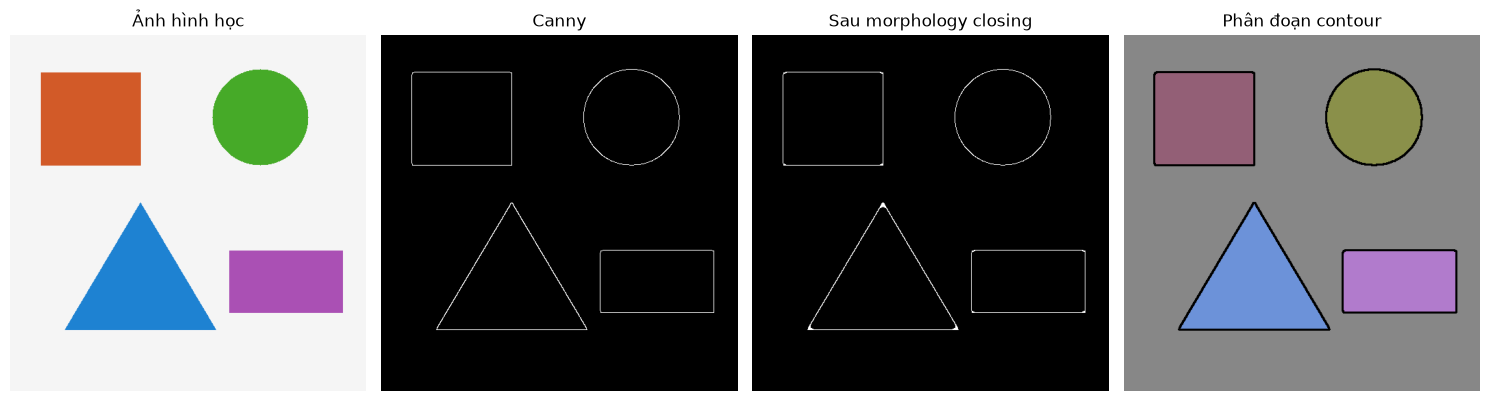

WindowsPath('results/IV1_phan_doan_contour.png')

In [12]:
def tao_anh_hinh_hoc(size=520):
    canvas = np.full((size, size, 3), 245, np.uint8)
    cv2.rectangle(canvas, (45, 55), (190, 190), (40, 90, 210), -1)
    cv2.circle(canvas, (365, 120), 70, (40, 170, 70), -1)
    pts = np.array([[80, 430], [190, 245], [300, 430]], np.int32)
    cv2.fillPoly(canvas, [pts], (210, 130, 30))
    cv2.rectangle(canvas, (320, 315), (485, 405), (180, 80, 170), -1)
    return canvas

shape_bgr = tao_anh_hinh_hoc()
shape_gray = cv2.cvtColor(shape_bgr, cv2.COLOR_BGR2GRAY)
shape_blur = cv2.GaussianBlur(shape_gray, (5, 5), 1.4)
shape_edges = cv2.Canny(shape_blur, 40, 120)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
shape_closed = cv2.morphologyEx(shape_edges, cv2.MORPH_CLOSE, kernel, iterations=2)
contours, _ = cv2.findContours(shape_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
min_area = 0.002 * shape_gray.size
contours = [c for c in contours if cv2.contourArea(c) > min_area]

segmentation = np.zeros_like(shape_bgr)
rng = np.random.default_rng(7)
for contour in contours:
    color = tuple(int(v) for v in rng.integers(60, 245, size=3))
    cv2.drawContours(segmentation, [contour], -1, color, thickness=cv2.FILLED)
overlay = cv2.addWeighted(shape_bgr, 0.55, segmentation, 0.45, 0)
cv2.drawContours(overlay, contours, -1, (0, 0, 0), 2)
print(f"Số vùng contour sau lọc diện tích: {len(contours)}")

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, im, title in zip(axes, [shape_bgr, shape_edges, shape_closed, overlay],
                         ["Ảnh hình học", "Canny", "Sau morphology closing", "Phân đoạn contour"]):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap=None if im.ndim == 3 else "gray")
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
save_img("IV1_anh_hinh_hoc.png", shape_bgr)
save_img("IV1_canny.png", shape_edges)
save_img("IV1_morphology_closing.png", shape_closed)
save_img("IV1_phan_doan_contour.png", overlay)


### 7.1. Nhận dạng hình dạng bằng contour

`approxPolyDP` xấp xỉ đường bao thành đa giác. Số đỉnh và độ tròn (circularity) được dùng làm đặc trưng đơn giản để gán nhãn.

,Nhãn dự đoán,Diện tích,Số đỉnh xấp xỉ,Circularity
0,Chữ nhật,15095.0,4,0.725
1,Tam giác,20637.0,3,0.557
2,Hình vuông,19845.0,4,0.791
3,Hình tròn,15414.0,8,0.900


Thống kê hình dạng: {'Chữ nhật': 1, 'Tam giác': 1, 'Hình vuông': 1, 'Hình tròn': 1}


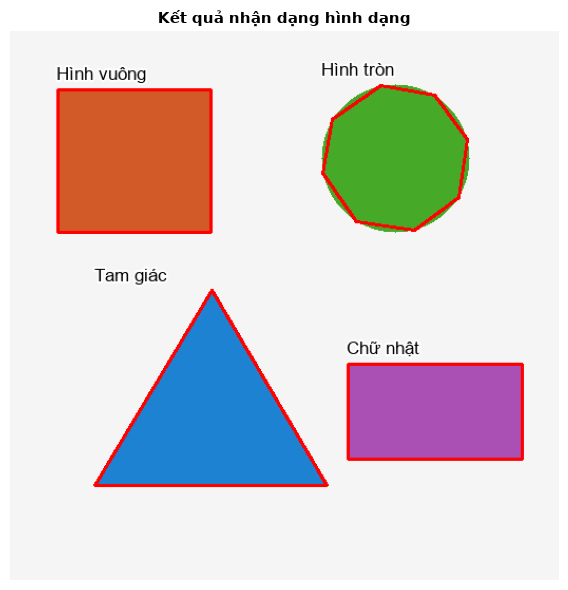

WindowsPath('results/IV2_nhan_dang_hinh_dang.png')

In [13]:
shape_result = shape_bgr.copy()
shape_counts = {}
shape_details = []
label_positions = []

for contour in contours:
    perimeter = cv2.arcLength(contour, True)
    if perimeter <= 0:
        continue
    approx = cv2.approxPolyDP(contour, 0.03 * perimeter, True)
    vertices = len(approx)
    area = cv2.contourArea(contour)
    circularity = 4 * np.pi * area / (perimeter * perimeter + 1e-9)

    if vertices == 3:
        label = "Tam giác"
    elif vertices == 4:
        x, y, w, h = cv2.boundingRect(approx)
        label = "Hình vuông" if 0.90 <= w / max(h, 1) <= 1.10 else "Chữ nhật"
    elif circularity > 0.80:
        label = "Hình tròn"
    elif vertices > 4:
        label = f"Đa giác ({vertices} đỉnh)"
    else:
        label = "Khác"

    shape_counts[label] = shape_counts.get(label, 0) + 1
    x, y, w, h = cv2.boundingRect(contour)
    cv2.drawContours(shape_result, [approx], -1, (0, 0, 255), 2)
    label_positions.append((label, x, max(2, y - 24)))
    shape_details.append([label, round(area, 1), vertices, round(circularity, 3)])

# PIL hỗ trợ chữ tiếng Việt có dấu tốt hơn cv2.putText.
from PIL import Image, ImageDraw, ImageFont
pil_result = Image.fromarray(cv2.cvtColor(shape_result, cv2.COLOR_BGR2RGB))
draw = ImageDraw.Draw(pil_result)
font_candidates = [
    "C:/Windows/Fonts/arial.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf"
]
font_path = next((f for f in font_candidates if os.path.exists(f)), None)
font = ImageFont.truetype(font_path, 17) if font_path else ImageFont.load_default()
for label, x, y in label_positions:
    draw.text((x, y), label, font=font, fill=(0, 0, 0),
              stroke_width=2, stroke_fill=(255, 255, 255))
shape_result = cv2.cvtColor(np.array(pil_result), cv2.COLOR_RGB2BGR)

display(pd.DataFrame(shape_details, columns=["Nhãn dự đoán", "Diện tích", "Số đỉnh xấp xỉ", "Circularity"]))
print("Thống kê hình dạng:", shape_counts)
show_grid([("Kết quả nhận dạng hình dạng", shape_result)], cols=1, figsize=(7, 6))
save_img("IV2_nhan_dang_hinh_dang.png", shape_result)


### 7.2. Phát hiện hình tròn bằng Hough Circle

Hough Circle là bước bổ sung để tìm đường tròn; thuật toán nhận ảnh xám đã làm trơn và tham số `param1` liên quan đến ngưỡng cao trong bộ phát hiện cạnh nội bộ của Hough.

Số hình tròn phát hiện bằng Hough: 1


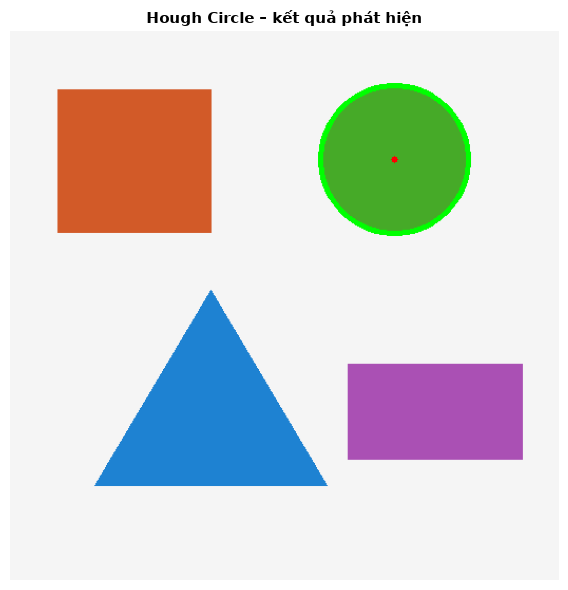

WindowsPath('results/IV3_hough_circle.png')

In [14]:
circles = cv2.HoughCircles(
    shape_blur, cv2.HOUGH_GRADIENT,
    dp=1.2, minDist=50,
    param1=120, param2=30,
    minRadius=20, maxRadius=120
)
hough_result = shape_bgr.copy()
if circles is not None:
    circles = np.round(circles[0]).astype(int)
    for x, y, radius in circles:
        cv2.circle(hough_result, (x, y), radius, (0, 255, 0), 3)
        cv2.circle(hough_result, (x, y), 3, (0, 0, 255), -1)
    print("Số hình tròn phát hiện bằng Hough:", len(circles))
else:
    print("Không phát hiện hình tròn. Có thể cần điều chỉnh param2/minDist/radius.")
show_grid([("Hough Circle – kết quả phát hiện", hough_result)], cols=1, figsize=(7, 6))
save_img("IV3_hough_circle.png", hough_result)


**Lưu ý về giới hạn:** phân đoạn contour từ Canny hoạt động tốt hơn khi biên khép kín và ít nhiễu. Nếu biên bị hở, contour có thể gộp vùng hoặc không bao quanh đúng đối tượng. Nhận dạng hình dạng bằng số đỉnh/circularity chỉ là phương pháp hình học cơ bản, có thể sai với vật thể méo, bị che khuất hoặc ảnh phối cảnh.

## 5. Kiểm tra và tổng kết kết quả

Tổng hợp các chỉ số chính và kiểm tra các file đầu ra trong `results/`.

In [15]:
# Tạo bảng tổng hợp các chỉ số quan sát được trong notebook.
final_summary = pd.DataFrame([
    ["OpenCV Canny", time_cv, edge_density(edges_cv)],
    ["Scikit-image Canny", time_sk, edge_density(edges_sk_u8)],
    ["OpenCV – mặc định 100/200", np.nan, edge_density(cv_default)],
    ["OpenCV – tùy chỉnh σ1.4, 40/120", np.nan, edge_density(cv_custom)],
    ["Scikit-image – mặc định", np.nan, edge_density(sk_default)],
    ["Scikit-image – tùy chỉnh", np.nan, edge_density(sk_custom)]
], columns=["Phương pháp", "Thời gian đo ở Bài 1 (ms)", "Tỷ lệ pixel cạnh (%)"])
display(final_summary.round(3))

csv_path = OUTPUT_DIR / "lab3_canny_tong_hop.csv"
final_summary.to_csv(csv_path, index=False, encoding="utf-8-sig")
print("Đã lưu bảng tổng hợp:", csv_path)


,Phương pháp,Thời gian đo ở Bài 1 (ms),Tỷ lệ pixel cạnh (%)
0,OpenCV Canny,0.478,3.120
1,Scikit-image Canny,14.264,2.494
2,OpenCV – mặc định 100/200,NaN,3.024
3,"OpenCV – tùy chỉnh σ1.4, 40/120",NaN,3.181
4,Scikit-image – mặc định,NaN,3.060
5,Scikit-image – tùy chỉnh,NaN,2.505


Đã lưu bảng tổng hợp: results\lab3_canny_tong_hop.csv


## 6. Kết luận chung

1. Canny có thể được thực hiện bằng OpenCV (`cv2.Canny`) và Scikit-image (`skimage.feature.canny`); cần chú ý thang ngưỡng của ảnh đầu vào.
2. Sigma điều khiển mức làm trơn; ngưỡng thấp/cao điều khiển việc giữ cạnh yếu và cạnh mạnh.
3. Ảnh nhiễu, ảnh tương phản thấp và ảnh nhiều chi tiết cần cấu hình khác nhau; không có một bộ tham số tối ưu cho mọi ảnh.
4. Kết hợp Canny với morphology và contour giúp tìm vùng có biên khép kín; kết hợp xấp xỉ đa giác/Hough hỗ trợ nhận dạng hình dạng đơn giản.
5. Ảnh tự nhiên được bổ sung để kiểm tra ngoài ảnh tạo có kiểm soát. Tỷ lệ pixel cạnh và thời gian chạy chỉ là chỉ số tham khảo; đánh giá độ chính xác cần ground truth hoặc tiêu chí của tác vụ cuối.
6. Phần câu hỏi mở rộng đã thảo luận cách đánh giá chất lượng, cải thiện Canny, ảnh màu và video.

**Trước khi nộp:** chạy `Run All`, kiểm tra ảnh và bảng kết quả, thay ảnh mẫu bằng ảnh thực tế nếu cần và tự viết nhận xét theo kết quả quan sát được.

## 7. Tài liệu đối chiếu

- Slide môn học: *Bài thực hành chương 2 (phần 2) – Canny Edge Detector*, trang 26 (yêu cầu thực hành và câu hỏi mở rộng).
- Rafael C. Gonzalez, Richard E. Woods, *Digital Image Processing*, 3rd Edition, phần phát hiện biên và thuật toán Canny (Chương 10).
- Mã nguồn gốc trong archive: `canny_so_sanh_opencv_skimage.py`, `canny_khao_sat_tham_so.py`, `canny_cac_loai_anh.py`, `canny_phan_doan_nhan_dang_hinh.py`, `canny_danh_gia_va_anh_mau.py`.

Phần lý thuyết và câu hỏi mở rộng được trình bày để phục vụ giải thích/bảo vệ. Ví dụ video là mã minh họa, không tự chạy vì cần file video đầu vào. Precision/Recall/F1 chỉ có ý nghĩa định lượng khi có ground truth.


## 8. CÂU HỎI MỞ RỘNG VÀ ĐÁNH GIÁ

### 8.1. Đánh giá chất lượng biên như thế nào?

Trong notebook này, **edge density** được dùng để mô tả tỷ lệ pixel được đánh dấu là cạnh; nó không phải độ chính xác. Ảnh có nhiều cạnh giả cũng có thể có edge density cao.

Nếu có bản đồ biên chuẩn (ground truth), có thể đối chiếu pixel dự đoán với pixel chuẩn để tính:
- **Precision:** trong các pixel được dự đoán là cạnh, tỷ lệ bao nhiêu là đúng.
- **Recall:** trong các pixel cạnh chuẩn, tỷ lệ bao nhiêu được phát hiện.
- **F1-score:** trung bình điều hòa giữa Precision và Recall.

Nếu không có ground truth, chỉ nên đánh giá định tính bằng độ liên tục, độ mảnh, mức nhiễu giả và khả năng phục vụ tác vụ tiếp theo. Không nên tuyên bố thuật toán chính xác hơn chỉ dựa vào edge density.

### 8.2. Có thể cải thiện Canny bằng cách nào?

- Khử nhiễu phù hợp trước khi phát hiện cạnh (Gaussian hoặc median tùy loại nhiễu).
- Chọn sigma và ngưỡng theo đặc điểm ảnh; thử nhiều cấu hình thay vì áp dụng một bộ cố định.
- Dùng ngưỡng tự động như một điểm khởi đầu, sau đó kiểm tra trực quan. Cách lấy ngưỡng theo median trong notebook chỉ là heuristic, không đảm bảo tối ưu.
- Dùng morphology closing khi cần nối các đoạn biên nhỏ bị đứt; cần tránh kernel lớn vì có thể nối nhầm hai đối tượng.
- Với ảnh phức tạp, kết hợp Canny với phân đoạn, contour hoặc mô hình học máy tùy mục tiêu.

### 8.3. Có thể áp dụng Canny cho ảnh màu không?

Có. Cách đơn giản và phổ biến là chuyển ảnh màu sang grayscale rồi áp dụng Canny. Tuy nhiên, bước chuyển xám có thể làm mất biên chỉ thể hiện rõ qua khác biệt màu sắc nhưng có độ sáng gần nhau. Một hướng khác là phát hiện gradient trên các kênh màu hoặc không gian màu phù hợp rồi kết hợp thông tin; cách này phức tạp hơn và cần quy tắc kết hợp rõ ràng.

### 8.4. Có thể áp dụng Canny cho video không?

Có. Video có thể được xử lý từng khung hình: đọc frame → chuyển grayscale → làm trơn → Canny → hiển thị hoặc ghi frame kết quả. Cần chú ý tốc độ xử lý để theo kịp tốc độ khung hình; Canny từng frame không tự đảm bảo tính ổn định theo thời gian, nên có thể cần lọc/ghép thông tin giữa các frame.

Ví dụ minh họa quy trình xử lý frame (chỉ chạy khi có file video hợp lệ):

```python
cap = cv2.VideoCapture("input/video.mp4")
while cap.isOpened():
    ok, frame = cap.read()
    if not ok:
        break
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    smooth = cv2.GaussianBlur(gray_frame, (5, 5), 1.4)
    edges = cv2.Canny(smooth, 50, 150)
    cv2.imshow("Canny video", edges)
    if cv2.waitKey(1) & 0xFF == 27:  # ESC để thoát
        break
cap.release()
cv2.destroyAllWindows()
```

### 8.5. Câu hỏi thường gặp khi bảo vệ

1. **Gaussian có tác dụng gì?** Giảm nhiễu trước khi tính gradient để hạn chế cạnh giả.
2. **Sigma tăng thì sao?** Ảnh mượt hơn, ít chi tiết nhỏ hơn; sigma quá lớn có thể làm mất biên thật.
3. **Tại sao cần hai ngưỡng?** Phân biệt biên mạnh/yếu; biên yếu chỉ được giữ nếu liên kết với biên mạnh.
4. **NMS dùng để làm gì?** Giữ cực đại gradient theo hướng biên để làm đường biên mảnh.
5. **Canny khác Sobel thế nào?** Sobel chủ yếu tính gradient; Canny có thêm làm trơn, NMS, hai ngưỡng và hysteresis.
6. **Vì sao OpenCV và Scikit-image khác kết quả?** Khác chi tiết cài đặt, quy ước/thang ngưỡng và mặc định; tham số quy đổi không bảo đảm kết quả giống hệt.
7. **Edge density có phải độ chính xác không?** Không. Nó chỉ là tỷ lệ pixel cạnh; muốn đo chính xác cần ground truth và các chỉ số như Precision, Recall, F1.
8. **Vì sao dùng morphology closing?** Để nối các đoạn biên gần nhau và khép khe hở nhỏ trước khi tìm contour.
9. **Contour và Hough Circle khác nhau thế nào?** Contour lấy đường bao vùng liên thông; Hough Circle tìm ứng viên hình tròn dựa trên biểu quyết hình học/gradient.
10. **Canny có xử lý ảnh màu trực tiếp không?** Các triển khai phổ biến thường yêu cầu ảnh đơn kênh; có thể chuyển grayscale hoặc xây dựng cách kết hợp gradient nhiều kênh.
